## 1. Carregar e conferir os arquivos

Este bloco procura os arquivos CSV na pasta `dados tratados`, considerando a execução pela raiz do projeto ou pela pasta `notebooks`. O Pandas identifica o separador e lê os arquivos com codificação UTF-8 com BOM. Em seguida, são removidos espaços no início e no fim dos nomes das colunas.

Os arquivos são identificados pelo nome: `dados_solo` corresponde à tabela `solo`, `cana` à tabela `cana` e `art` à tabela de preços `art`. As tabelas também ficam reunidas no dicionário `bases`. Os arquivos de solo e cana são obrigatórios; se algum deles não for encontrado, o código interrompe a execução com uma mensagem. A tabela de preços é opcional e não participa das análises seguintes.

Ao final, são exibidos o tamanho, as colunas, as três primeiras linhas e a quantidade de valores ausentes de cada tabela. Essa conferência não preenche ausências nem remove registros. Os arquivos originais não são alterados.


In [1]:
from pathlib import Path
import pandas as pd
import io

# Leia os CSVs da pasta dados tratados, na raiz do projeto.
pasta_dados = Path("dados tratados")
if not pasta_dados.is_dir():
    pasta_dados = Path("..") / "dados tratados"

arquivos_enviados = {}
for arquivo in sorted(pasta_dados.glob("*.csv")):
    arquivos_enviados[arquivo.name] = arquivo.read_bytes()

bases = {}
solo = None
cana = None
art = None

for nome_arquivo in arquivos_enviados:
    conteudo = arquivos_enviados[nome_arquivo]

    tabela = pd.read_csv(
        io.BytesIO(conteudo),
        sep=None,
        engine="python",
        encoding="utf-8-sig"
    )

    # Remove espaços acidentais do início e do fim dos nomes das colunas.
    colunas_limpas = []

    for nome_coluna in tabela.columns:
        colunas_limpas.append(nome_coluna.strip())

    tabela.columns = colunas_limpas
    bases[nome_arquivo.lower()] = tabela

    nome_minusculo = nome_arquivo.lower()

    if "dados_solo" in nome_minusculo:
        solo = tabela
    elif "cana" in nome_minusculo:
        cana = tabela
    elif "art" in nome_minusculo:
        art = tabela

if solo is None:
    raise ValueError("Não encontrei o arquivo DADOS_SOLO.")

if cana is None:
    raise ValueError("Não encontrei o arquivo Cana.csv.")

for nome_arquivo in bases:
    tabela = bases[nome_arquivo]

    print("\nArquivo:", nome_arquivo)
    print("Dimensões:", tabela.shape)
    print("Colunas:", list(tabela.columns))
    print("Primeiras três linhas:")
    print(tabela.head(3).to_string(index=False))

    print("Valores ausentes por coluna:")
    for nome_coluna in tabela.columns:
        ausentes = tabela[nome_coluna].isna().sum()

        if ausentes > 0:
            print(nome_coluna, ":", ausentes)


Arquivo: cana.csv
Dimensões: (21, 25)
Colunas: ['Data_Geracao', 'Data_Inicial', 'Data_Final', 'Fornecedor', 'Unidade_Industrial', 'Fazenda', 'Linha', 'Distancia', 'Ton', 'Pct_Cana', 'Cargas_Ent', 'Cargas_Ant', 'Pct_Ant', 'Dens', 'Brix', 'Pol', 'Pza', 'Ar', 'PC', 'Fibra', 'AR_Calc', 'ATR', 'TMP', 'Imp', 'Pct_Broca']
Primeiras três linhas:
       Data_Geracao Data_Inicial Data_Final            Fornecedor  Unidade_Industrial                  Fazenda              Linha  Distancia      Ton  Pct_Cana  Cargas_Ent  Cargas_Ant  Pct_Ant   Dens  Brix   Pol   Pza   Ar    PC  Fibra  AR_Calc   ATR  TMP  Imp  Pct_Broca
13/10/2026 14:30:54   01/04/2020 31/12/2020 7791 - LUIS CESAR PIO                  15 51332 - FAZENDA SAO JOAO            Fazenda       29.0 18642.20     100.0       596.0       186.0     30.8 31.300 19.40 16.50 84.80 0.70 13.80  12.60     0.60 138.4  2.0 0.50        0.0
13/10/2026 14:30:54   01/04/2020 31/12/2020 7791 - LUIS CESAR PIO                  15                      NaN Tota

## 2. Preparar as tabelas anuais

Este bloco trabalha com cópias das tabelas de solo e cana. Converte as datas no formato dia/mês/ano, transformando datas inválidas em valores ausentes. O ano do solo é extraído de `Data`; o da cana, de `Data_Final`. Portanto, o pareamento atual utiliza **ano civil**, não uma safra agrícola definida por início e fim.

Na tabela de cana, são mantidas somente as linhas com `Linha` igual a `Fazenda` e identificação de fazenda preenchida. Isso evita somar as linhas de totais junto aos detalhes. Se não houver registros desse tipo, a execução é interrompida.

Para o solo, os laços calculam primeiro a média dos valores disponíveis por ano, propriedade e talhão. Depois, calculam a média anual dessas médias, dando o mesmo peso a cada combinação de propriedade e talhão com valor disponível. As profundidades não são separadas nesse cálculo. Quando não há valores para uma variável, o resultado permanece ausente.

Para a cana, tonelagem e quantidades de cargas são somadas por ano. Os demais indicadores, incluindo ATR, são calculados por média ponderada pela tonelagem, considerando apenas pares preenchidos com tonelagem positiva.

Por fim, o código reúne os anos presentes nas duas bases em `dados_anual`, exibe os anos e a tabela resultante e interrompe a execução se não houver anos em comum. **A junção final é apenas pelo ano:** não valida correspondência entre propriedades. Se houver várias propriedades, os resumos anuais podem misturá-las. Essa tabela é exploratória e não equivale a uma base de ATR por talhão.


In [2]:
solo_trabalho = solo.copy()
cana_trabalho = cana.copy()

# Converte as datas no formato dia/mês/ano.
solo_trabalho["Data"] = pd.to_datetime(
    solo_trabalho["Data"],
    format="%d/%m/%Y",
    errors="coerce"
)

cana_trabalho["Data_Inicial"] = pd.to_datetime(
    cana_trabalho["Data_Inicial"],
    format="%d/%m/%Y",
    errors="coerce"
)

cana_trabalho["Data_Final"] = pd.to_datetime(
    cana_trabalho["Data_Final"],
    format="%d/%m/%Y",
    errors="coerce"
)

# Por enquanto, associa os dados pelo ano civil.
solo_trabalho["Ano"] = solo_trabalho["Data"].dt.year
cana_trabalho["Ano"] = cana_trabalho["Data_Final"].dt.year

# Mostra os níveis de resumo existentes na coluna Linha.
linhas_resumo = []

for indice in range(len(cana_trabalho)):
    valor = cana_trabalho["Linha"].iloc[indice]

    if pd.notna(valor) and valor not in linhas_resumo:
        linhas_resumo.append(valor)

print("Valores encontrados em Linha:", linhas_resumo)

# Mantém somente as linhas detalhadas da fazenda.
indices_fazenda = []

for indice in range(len(cana_trabalho)):
    linha = cana_trabalho["Linha"].iloc[indice]
    nome_fazenda = cana_trabalho["Fazenda"].iloc[indice]

    if (
        pd.notna(linha)
        and str(linha).strip().lower() == "fazenda"
        and pd.notna(nome_fazenda)
    ):
        indices_fazenda.append(indice)

cana_fazenda = cana_trabalho.iloc[indices_fazenda].copy()

print("Linhas detalhadas de fazenda:", len(cana_fazenda))
print(
    cana_fazenda[
        ["Data_Inicial", "Data_Final", "Fazenda", "Ton", "ATR"]
    ].to_string(index=False)
)

if len(cana_fazenda) == 0:
    raise ValueError(
        "Não encontrei linhas com Linha igual a 'Fazenda'. "
        "Confira os valores impressos em Linha."
    )

# Atributos do solo numéricos mostrados no arquivo.
variaveis_solo = [
    "ph do solo",
    "materia organica",
    "fosforo",
    "potassio",
    "calcio",
    "magnesio",
    "acidez potencial",
    "bases",
    "CTC",
    "saturacao por bases",
    "enxofre",
    "ferro",
    "manganes",
    "zinco",
    "cobre",
    "aluminio",
    "argila",
    "areia_grossa",
    "areia_fina",
    "areia_total",
    "silte"
]

# Confere se todos os nomes esperados estão presentes.
for nome_variavel in variaveis_solo:
    if nome_variavel not in solo_trabalho.columns:
        print("Coluna de solo ausente:", nome_variavel)

# Agrupa as amostras por ano, propriedade e talhão.
chaves_talhao_ano = []

for indice in range(len(solo_trabalho)):
    ano = solo_trabalho["Ano"].iloc[indice]
    propriedade = solo_trabalho["propriedade"].iloc[indice]
    talhao = solo_trabalho["talhao"].iloc[indice]

    if pd.notna(ano) and pd.notna(propriedade) and pd.notna(talhao):
        chave = (
            int(ano),
            str(propriedade).strip(),
            str(talhao).strip()
        )

        if chave not in chaves_talhao_ano:
            chaves_talhao_ano.append(chave)

# Calcula uma média por variável dentro de cada talhão e ano.
solo_por_talhao_ano = []

for chave in chaves_talhao_ano:
    ano_chave = chave[0]
    propriedade_chave = chave[1]
    talhao_chave = chave[2]

    registro = {
        "Ano": ano_chave,
        "propriedade": propriedade_chave,
        "talhao": talhao_chave
    }

    for nome_variavel in variaveis_solo:
        if nome_variavel in solo_trabalho.columns:
            soma = 0
            quantidade = 0

            for indice in range(len(solo_trabalho)):
                ano = solo_trabalho["Ano"].iloc[indice]
                propriedade = solo_trabalho["propriedade"].iloc[indice]
                talhao = solo_trabalho["talhao"].iloc[indice]
                valor = solo_trabalho[nome_variavel].iloc[indice]

                mesma_chave = (
                    pd.notna(ano)
                    and pd.notna(propriedade)
                    and pd.notna(talhao)
                    and int(ano) == ano_chave
                    and str(propriedade).strip() == propriedade_chave
                    and str(talhao).strip() == talhao_chave
                )

                if mesma_chave and pd.notna(valor):
                    soma = soma + float(valor)
                    quantidade = quantidade + 1

            if quantidade > 0:
                registro[nome_variavel] = soma / quantidade
            else:
                registro[nome_variavel] = None

    solo_por_talhao_ano.append(registro)

# Calcula a média anual dando o mesmo peso a cada talhão.
anos_solo = []

for registro in solo_por_talhao_ano:
    if registro["Ano"] not in anos_solo:
        anos_solo.append(registro["Ano"])

solo_anual = []

for ano in anos_solo:
    registro_anual = {"Ano": ano}
    quantidade_talhoes = 0

    for registro in solo_por_talhao_ano:
        if registro["Ano"] == ano:
            quantidade_talhoes = quantidade_talhoes + 1

    registro_anual["N_Talhoes"] = quantidade_talhoes

    for nome_variavel in variaveis_solo:
        soma = 0
        quantidade = 0

        for registro in solo_por_talhao_ano:
            valor = registro.get(nome_variavel)

            if registro["Ano"] == ano and valor is not None:
                soma = soma + valor
                quantidade = quantidade + 1

        if quantidade > 0:
            registro_anual[nome_variavel] = soma / quantidade
        else:
            registro_anual[nome_variavel] = None

    solo_anual.append(registro_anual)

# Agrupa informações da cana por ano.
# Ton e cargas são somados. As demais medidas são médias ponderadas por Ton.
variaveis_soma_cana = ["Ton", "Cargas_Ent", "Cargas_Ant"]

variaveis_ponderadas_cana = [
    "Pct_Cana",
    "Pct_Ant",
    "Dens",
    "Brix",
    "Pol",
    "Pza",
    "Ar",
    "PC",
    "Fibra",
    "AR_Calc",
    "ATR",
    "TMP",
    "Imp",
    "Pct_Broca"
]

anos_cana = []

for indice in range(len(cana_fazenda)):
    ano = cana_fazenda["Ano"].iloc[indice]

    if pd.notna(ano) and int(ano) not in anos_cana:
        anos_cana.append(int(ano))

cana_anual = []

for ano in anos_cana:
    registro_anual = {"Ano": ano}
    quantidade_registros = 0

    for indice in range(len(cana_fazenda)):
        ano_linha = cana_fazenda["Ano"].iloc[indice]

        if pd.notna(ano_linha) and int(ano_linha) == ano:
            quantidade_registros = quantidade_registros + 1

    registro_anual["N_Registros_Cana"] = quantidade_registros

    for nome_variavel in variaveis_soma_cana:
        if nome_variavel in cana_fazenda.columns:
            soma = 0
            quantidade = 0

            for indice in range(len(cana_fazenda)):
                ano_linha = cana_fazenda["Ano"].iloc[indice]
                valor = cana_fazenda[nome_variavel].iloc[indice]

                if (
                    pd.notna(ano_linha)
                    and int(ano_linha) == ano
                    and pd.notna(valor)
                ):
                    soma = soma + float(valor)
                    quantidade = quantidade + 1

            if quantidade > 0:
                registro_anual[nome_variavel] = soma
            else:
                registro_anual[nome_variavel] = None

    for nome_variavel in variaveis_ponderadas_cana:
        if nome_variavel in cana_fazenda.columns:
            soma_ponderada = 0
            soma_toneladas = 0

            for indice in range(len(cana_fazenda)):
                ano_linha = cana_fazenda["Ano"].iloc[indice]
                valor = cana_fazenda[nome_variavel].iloc[indice]
                toneladas = cana_fazenda["Ton"].iloc[indice]

                if (
                    pd.notna(ano_linha)
                    and int(ano_linha) == ano
                    and pd.notna(valor)
                    and pd.notna(toneladas)
                    and toneladas > 0
                ):
                    soma_ponderada = soma_ponderada + float(valor) * float(toneladas)
                    soma_toneladas = soma_toneladas + float(toneladas)

            if soma_toneladas > 0:
                registro_anual[nome_variavel] = (
                    soma_ponderada / soma_toneladas
                )
            else:
                registro_anual[nome_variavel] = None

    cana_anual.append(registro_anual)

# Combina somente os anos que existem nas duas tabelas.
dados_combinados = []

for registro_solo in solo_anual:
    for registro_cana in cana_anual:
        if registro_solo["Ano"] == registro_cana["Ano"]:
            registro = {
                "Ano": registro_solo["Ano"],
                "N_Talhoes": registro_solo["N_Talhoes"]
            }

            for nome_variavel in variaveis_solo:
                registro[nome_variavel] = registro_solo.get(nome_variavel)

            for nome_variavel in variaveis_soma_cana:
                registro[nome_variavel] = registro_cana.get(nome_variavel)

            for nome_variavel in variaveis_ponderadas_cana:
                registro[nome_variavel] = registro_cana.get(nome_variavel)

            dados_combinados.append(registro)

dados_anual = pd.DataFrame(dados_combinados)

print("Anos com dados de solo:", anos_solo)
print("Anos com dados de cana:", anos_cana)

if len(dados_anual) == 0:
    raise ValueError(
        "Não encontrei anos em comum. Confira as datas e a regra de pareamento."
    )

print("Quantidade de anos pareados:", len(dados_anual))
print("Tabela anual usada na análise:")
print(dados_anual.to_string(index=False))

Valores encontrados em Linha: ['Fazenda', 'Total (Fornecedor)', 'Total (Geral)']
Linhas detalhadas de fazenda: 7
Data_Inicial Data_Final                  Fazenda     Ton   ATR
  2020-04-01 2020-12-31 51332 - FAZENDA SAO JOAO 18642.2 138.4
  2021-04-01 2021-12-31 51332 - FAZENDA SAO JOAO 10842.8 140.5
  2022-04-01 2022-12-31 51332 - FAZENDA SAO JOAO 14428.7 143.7
  2023-04-01 2023-12-31 51332 - FAZENDA SAO JOAO 11928.1 133.4
  2024-04-01 2024-12-31 51332 - FAZENDA SAO JOAO 14001.7 127.2
  2025-04-01 2025-12-31 51332 - FAZENDA SAO JOAO 13109.3 122.7
  2026-04-01 2026-12-31 51332 - FAZENDA SAO JOAO 13930.1 125.9
Anos com dados de solo: [2021, 2023, 2024, 2025, 2022, 2020]
Anos com dados de cana: [2020, 2021, 2022, 2023, 2024, 2025, 2026]
Quantidade de anos pareados: 6
Tabela anual usada na análise:
 Ano  N_Talhoes  ph do solo  materia organica   fosforo  potassio    calcio  magnesio  acidez potencial     bases       CTC  saturacao por bases  enxofre     ferro  manganes    zinco    cobre  

## 3. Calcular correlações de Pearson com laços

A função `correlacao_pearson` recebe duas listas e mantém somente os pares em que ambos os valores estão preenchidos. Com laços, calcula as médias, os desvios em relação às médias e o coeficiente de Pearson. A função retorna o coeficiente e a quantidade de pares utilizados; retorna correlação não calculável quando há menos de três pares ou quando uma das variáveis não apresenta variação.

O código aplica essa função às variáveis de solo e de cana em relação ao ATR da tabela anual. Para cada variável, apresenta `r` e o número de anos válidos. Valores de `r` próximos de 1 indicam associação linear positiva; próximos de -1, associação negativa; próximos de zero, pouca associação linear.

Esses resultados descrevem associações na amostra, não demonstram causa e efeito nem treinam uma regressão. Com poucos anos, os coeficientes devem ser interpretados com cuidado. Indicadores de laboratório relacionados ao cálculo do ATR também não devem ser automaticamente tratados como preditores disponíveis antes da colheita.


In [3]:
def correlacao_pearson(valores_x, valores_y):
    x_validos = []
    y_validos = []

    for indice in range(len(valores_x)):
        valor_x = valores_x[indice]
        valor_y = valores_y[indice]

        if pd.notna(valor_x) and pd.notna(valor_y):
            x_validos.append(float(valor_x))
            y_validos.append(float(valor_y))

    quantidade = len(x_validos)

    if quantidade < 3:
        return None, quantidade

    soma_x = 0
    soma_y = 0

    for indice in range(quantidade):
        soma_x = soma_x + x_validos[indice]
        soma_y = soma_y + y_validos[indice]

    media_x = soma_x / quantidade
    media_y = soma_y / quantidade

    soma_produtos = 0
    soma_quadrados_x = 0
    soma_quadrados_y = 0

    for indice in range(quantidade):
        diferenca_x = x_validos[indice] - media_x
        diferenca_y = y_validos[indice] - media_y

        soma_produtos = soma_produtos + diferenca_x * diferenca_y
        soma_quadrados_x = soma_quadrados_x + diferenca_x * diferenca_x
        soma_quadrados_y = soma_quadrados_y + diferenca_y * diferenca_y

    denominador = (soma_quadrados_x * soma_quadrados_y) ** 0.5

    if denominador == 0:
        return None, quantidade

    correlacao = soma_produtos / denominador

    return correlacao, quantidade


print("CORRELAÇÃO DAS CARACTERÍSTICAS DO SOLO COM ATR")

for nome_variavel in variaveis_solo:
    if nome_variavel in dados_anual.columns:
        valores_x = []
        valores_atr = []

        for indice in range(len(dados_anual)):
            valores_x.append(dados_anual[nome_variavel].iloc[indice])
            valores_atr.append(dados_anual["ATR"].iloc[indice])

        r, quantidade = correlacao_pearson(valores_x, valores_atr)

        if r is None:
            print(nome_variavel, "| não calculável | anos válidos:", quantidade)
        else:
            print(nome_variavel, "| r =", round(r, 3), "| anos válidos:", quantidade)


variaveis_cana_com_atr = [
    "Ton",
    "Pct_Cana",
    "Cargas_Ent",
    "Cargas_Ant",
    "Pct_Ant",
    "Dens",
    "Brix",
    "Pol",
    "Pza",
    "Ar",
    "PC",
    "Fibra",
    "AR_Calc",
    "TMP",
    "Imp",
    "Pct_Broca"
]

print("\nCORRELAÇÃO DAS INFORMAÇÕES DA CANA COM ATR")

for nome_variavel in variaveis_cana_com_atr:
    if nome_variavel in dados_anual.columns:
        valores_x = []
        valores_atr = []

        for indice in range(len(dados_anual)):
            valores_x.append(dados_anual[nome_variavel].iloc[indice])
            valores_atr.append(dados_anual["ATR"].iloc[indice])

        r, quantidade = correlacao_pearson(valores_x, valores_atr)

        if r is None:
            print(nome_variavel, "| não calculável | anos válidos:", quantidade)
        else:
            print(nome_variavel, "| r =", round(r, 3), "| anos válidos:", quantidade)

CORRELAÇÃO DAS CARACTERÍSTICAS DO SOLO COM ATR
ph do solo | r = -0.906 | anos válidos: 6
materia organica | r = -0.485 | anos válidos: 6
fosforo | r = -0.098 | anos válidos: 6
potassio | r = -0.278 | anos válidos: 6
calcio | r = -0.933 | anos válidos: 6
magnesio | r = -0.954 | anos válidos: 6
acidez potencial | r = 0.868 | anos válidos: 6
bases | r = -0.971 | anos válidos: 6
CTC | r = -0.944 | anos válidos: 6
saturacao por bases | r = -0.934 | anos válidos: 6
enxofre | r = -0.645 | anos válidos: 6
ferro | r = -0.363 | anos válidos: 6
manganes | r = -0.266 | anos válidos: 6
zinco | r = -0.831 | anos válidos: 6
cobre | r = -0.421 | anos válidos: 6
aluminio | r = 0.828 | anos válidos: 6
argila | r = 0.599 | anos válidos: 3
areia_grossa | r = 0.785 | anos válidos: 3
areia_fina | r = 0.648 | anos válidos: 3
areia_total | r = 0.703 | anos válidos: 3
silte | r = -0.685 | anos válidos: 3

CORRELAÇÃO DAS INFORMAÇÕES DA CANA COM ATR
Ton | r = 0.143 | anos válidos: 6
Pct_Cana | não calculável | a

## 4. Visualizar e conferir as correlações

**Bloco de definição do gráfico:** a função `criar_grafico_correlacoes` utiliza a função de Pearson já definida e reúne somente as correlações calculáveis com o ATR. Cria barras horizontais verdes para associações positivas ou nulas e vermelhas para negativas. Os rótulos mostram o coeficiente `r` e a quantidade `n` de anos válidos. O eixo varia de -1 a 1. Se nenhuma correlação puder ser calculada, a função exibe uma mensagem.

**Bloco de chamadas dos gráficos:** executa a função duas vezes, gerando uma visualização para os atributos do solo e outra para os indicadores da cana. Os dois gráficos utilizam `dados_anual`; não representam análises por amostra ou por talhão individual.

**Bloco da matriz de correlação:** percorre uma lista selecionada de variáveis e calcula Pearson para cada par. Organiza os coeficientes em uma matriz, desenha o mapa de cores e escreve os valores nas células. Esse bloco pressupõe que todas as colunas selecionadas existam e que os coeficientes sejam calculáveis; valores ausentes ou variáveis constantes podem impedir sua exibição no código atual.

**Bloco de conferência do Brix:** apresenta média, mínimo e máximo de Brix e a matriz de correlação entre Brix e ATR com o método `corr()` do Pandas. Diferentemente dos gráficos anteriores, utiliza a tabela `cana` carregada originalmente, sem o filtro de linhas de fazenda e sem agregação anual. Se a tabela incluir totais repetidos, eles também participarão desses cálculos; os resultados não devem ser confundidos com os da tabela anual.

Execute os blocos na ordem em que aparecem, pois eles dependem das tabelas e funções criadas anteriormente. Esta etapa é exploratória: não faz divisão em treino/teste e não ajusta o modelo de regressão linear simples.


In [7]:
import matplotlib.pyplot as plt


def criar_grafico_correlacoes(variaveis, titulo, altura):
    nomes = []
    correlacoes = []
    cores = []

    for nome_variavel in variaveis:
        if nome_variavel in dados_anual.columns:
            valores_x = []
            valores_atr = []

            for indice in range(len(dados_anual)):
                valores_x.append(dados_anual[nome_variavel].iloc[indice])
                valores_atr.append(dados_anual["ATR"].iloc[indice])

            r, quantidade = correlacao_pearson(valores_x, valores_atr)

            if r is not None:
                nomes.append(
                    nome_variavel
                    + " (r="
                    + str(round(r, 2))
                    + ", n="
                    + str(quantidade)
                    + ")"
                )
                correlacoes.append(r)

                if r >= 0:
                    cores.append("seagreen")
                else:
                    cores.append("indianred")

    if len(correlacoes) == 0:
        print("Não há correlações calculáveis para:", titulo)
    else:
        plt.figure(figsize=(10, altura))
        plt.barh(nomes, correlacoes, color=cores)
        plt.axvline(x=0, color="black", linewidth=1)
        plt.xlim(-1, 1)
        plt.xlabel("Correlação de Pearson (r)")
        plt.title(titulo)
        plt.grid(axis="x", linestyle="--", alpha=0.4)
        plt.tight_layout()
        plt.show()

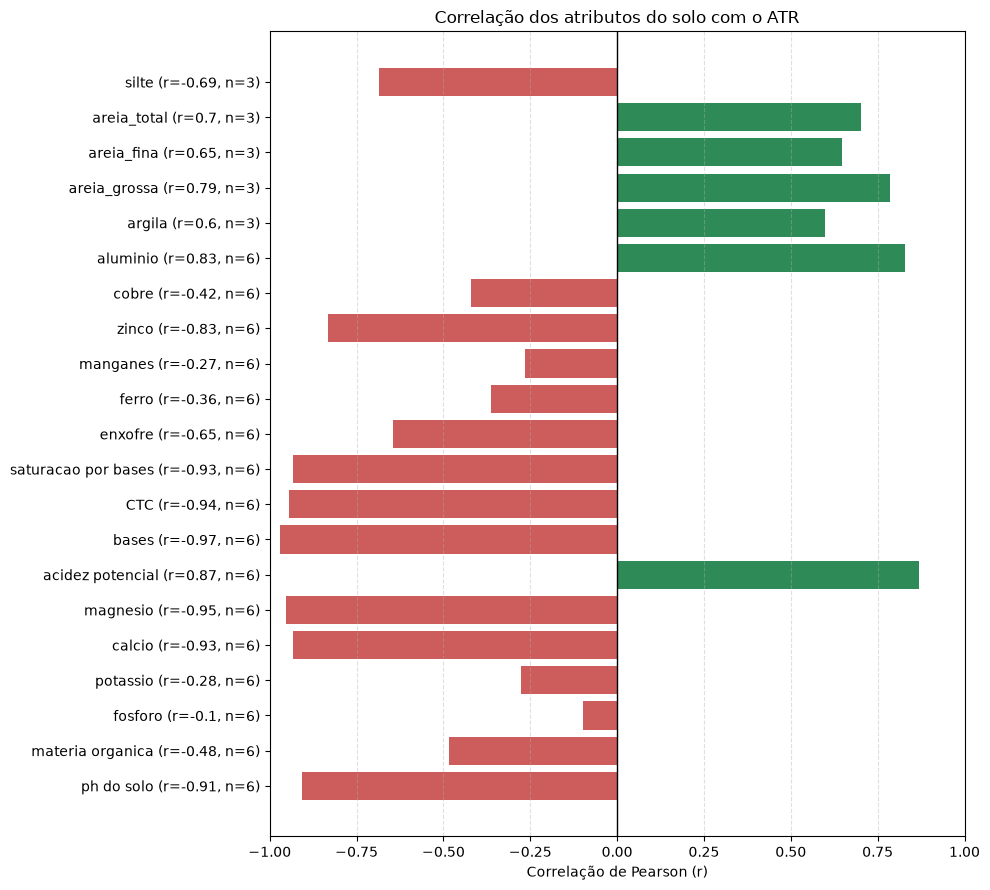

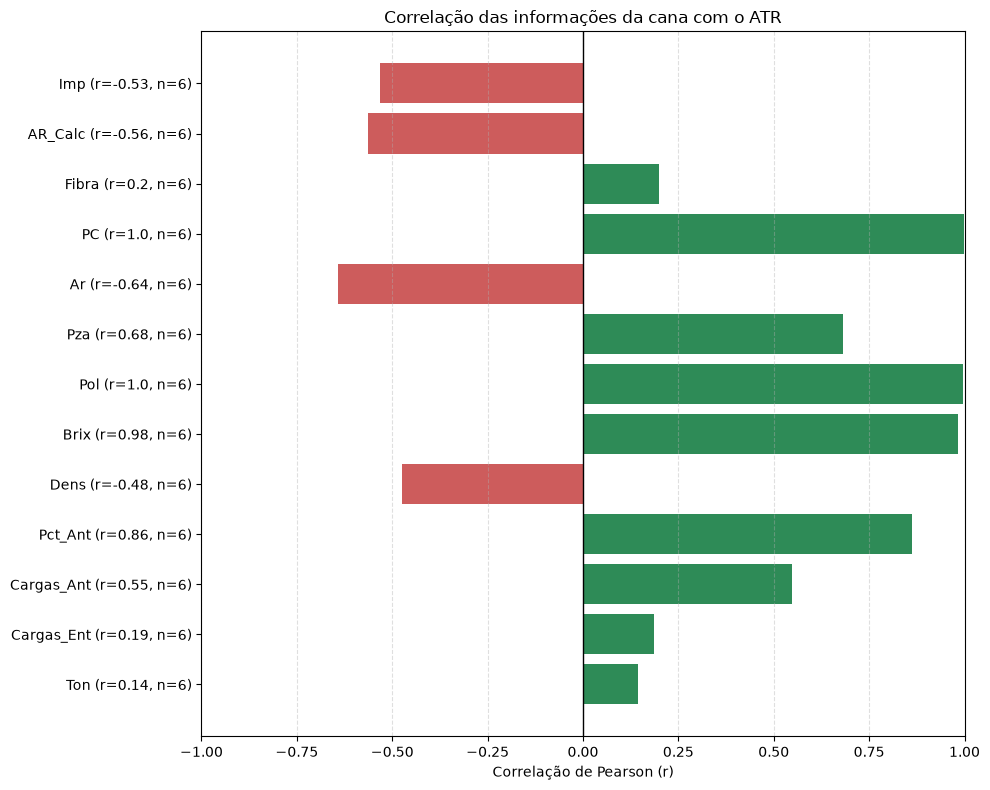

In [8]:
criar_grafico_correlacoes(
    variaveis_solo,
    "Correlação dos atributos do solo com o ATR",
    9
)

criar_grafico_correlacoes(
    variaveis_cana_com_atr,
    "Correlação das informações da cana com o ATR",
    8
)

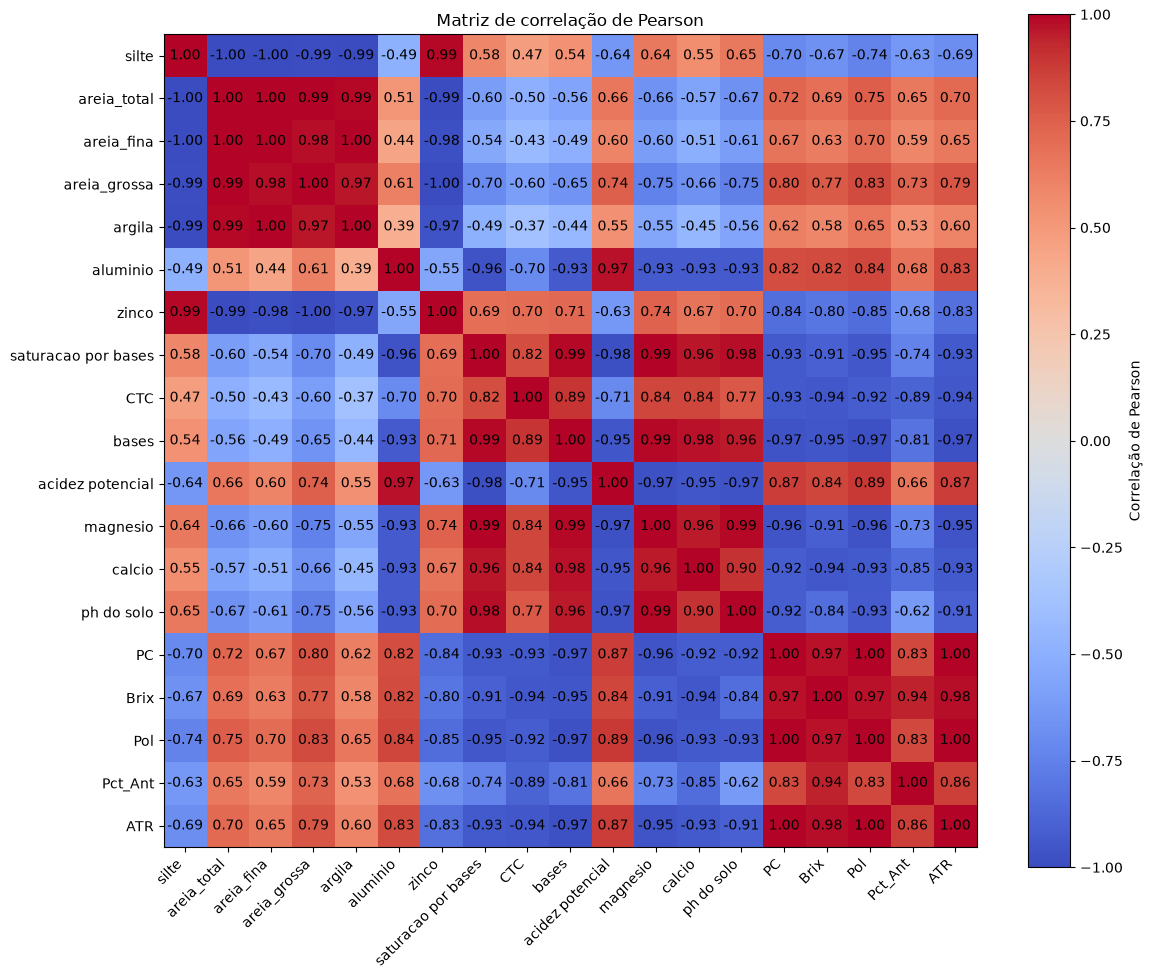

In [9]:
import matplotlib.pyplot as plt

variaveis = [
    "silte",
    "areia_total",
    "areia_fina",
    "areia_grossa",
    "argila",
    "aluminio",
    "zinco",
    "saturacao por bases",
    "CTC",
    "bases",
    "acidez potencial",
    "magnesio",
    "calcio",
    "ph do solo",
    "PC",
    "Brix",
    "Pol",
    "Pct_Ant",
    "ATR"
]

# Começa uma matriz vazia.
matriz_correlacoes = []

# Cada linha da matriz corresponde a uma variável.
for nome_x in variaveis:
    linha_correlacoes = []

    # Cada coluna corresponde à variável com a qual será calculada a correlação.
    for nome_y in variaveis:
        valores_x = []
        valores_y = []

        # Monta duas listas com os valores das colunas.
        for indice in range(len(dados_anual)):
            valor_x = dados_anual[nome_x].iloc[indice]
            valor_y = dados_anual[nome_y].iloc[indice]

            # Só usa pares em que os dois valores existem.
            if valor_x == valor_x and valor_y == valor_y:
                valores_x.append(valor_x)
                valores_y.append(valor_y)

        # Ajuste esta chamada se a sua função receber os argumentos em outra ordem.
        resultado = correlacao_pearson(valores_x, valores_y)

        # No código anterior, a função retornava (correlacao, quantidade).
        correlacao = resultado[0]

        # Guarda a correlação na linha atual.
        linha_correlacoes.append(correlacao)

    matriz_correlacoes.append(linha_correlacoes)

# Desenha a matriz calculada.
plt.figure(figsize=(12, 10))
grafico = plt.imshow(
    matriz_correlacoes,
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

plt.colorbar(grafico, label="Correlação de Pearson")
plt.xticks(range(len(variaveis)), variaveis, rotation=45, ha="right")
plt.yticks(range(len(variaveis)), variaveis)

# Escreve os coeficientes dentro das células.
for linha in range(len(matriz_correlacoes)):
    for coluna in range(len(matriz_correlacoes[linha])):
        valor = matriz_correlacoes[linha][coluna]
        plt.text(coluna, linha, f"{valor:.2f}", ha="center", va="center")

plt.title("Matriz de correlação de Pearson")
plt.tight_layout()
plt.show()

In [10]:
print("Média do Brix:", cana["Brix"].mean())
print("Brix mínimo:", cana["Brix"].min())
print("Brix máximo:", cana["Brix"].max())

print(cana[["Brix", "ATR"]].corr())

Média do Brix: 18.87047619047619
Brix mínimo: 17.6
Brix máximo: 20.3
          Brix       ATR
Brix  1.000000  0.982255
ATR   0.982255  1.000000
